In [93]:
import copy
import json
import os
import re
import threading
import uuid
from collections.abc import Callable, Iterable
from contextlib import contextmanager
from dataclasses import dataclass, field
from datetime import datetime
from decimal import ROUND_HALF_UP, Decimal, InvalidOperation
from enum import Enum
from pathlib import Path

import pandas as pd

# ------------ Регулярки
# Одно слово: заглавная + строчные, допускается двойное через дефис (Анна-Мария)
_LAT_WORD = r"[A-Z][a-z]+(?:-[A-Z][a-z]+)?"
_CYR_WORD = r"[А-ЯЁ][а-яё]+(?:-[А-ЯЁ][а-яё]+)?"

# «Имя Фамилия»: оба слова латиницей ИЛИ оба кириллицей
BA_FULL_NAME_RE = re.compile(
    rf"{_LAT_WORD} {_LAT_WORD}|{_CYR_WORD} {_CYR_WORD}"
)
ACC_ID_RE = re.compile(r"^ACC-\d{4}$")


# ------------ Enums

class OperationType(Enum):
    DEPOSIT = "deposit"
    WITHDRAW = "withdraw"
    INTEREST = "interest"  # начисление процентов (только сберегательный счёт)


class MoneyTransactionStatus(Enum):
    FAIL = "fail"
    SUCCESS = "success"


class AccountType(Enum):
    CHECKING = "checking"  # расчётный
    SAVINGS = "savings"  # сберегательный


# ------------ Модели
class MoneyTransaction:
    def __init__(
            self,
            operation: OperationType,
            amount: int | Decimal,
            date: datetime,
            balance_after: int | Decimal,
            status: MoneyTransactionStatus,
            *,
            transfer_id: str | None = None,
            counterparty: str | None = None,
            reason: str | None = None
    ):
        # OperationType(...) / MoneyTransactionStatus(...) принимают и сам Enum,
        # и строку "deposit"/"success" - это нужно при чтении из JSON
        self.operation = OperationType(operation)
        self.amount = Decimal(amount)
        self.date = date
        self.balance_after = Decimal(balance_after)
        self.status = MoneyTransactionStatus(status)
        # Для перевода: общий id у списания и зачисления + номер второго счёта
        self.transfer_id = transfer_id
        self.counterparty = counterparty
        # Почему операция неуспешна (заполняется для fail)
        self.reason = reason

    @property
    def is_success(self) -> bool:
        return self.status is MoneyTransactionStatus.SUCCESS

    def __str__(self) -> str:
        """Одна строка истории в читаемом виде."""
        line = (
            f"{self.date:%Y-%m-%d %H:%M:%S} | {self.operation.value:<8} | "
            f"{self.amount:>12,.2f} | balance after: {self.balance_after:>14,.2f} | "
            f"{self.status.value}"
        )
        if self.transfer_id is not None:
            direction = "to" if self.operation is OperationType.WITHDRAW else "from"
            line += f" | transfer {self.transfer_id} {direction} {self.counterparty}"
        if self.reason is not None:
            line += f" | {self.reason}"
        return line

    def __repr__(self) -> str:
        return (
            f"MoneyTransaction({self.operation.value}, {self.amount}, "
            f"{self.date.isoformat(timespec='seconds')}, "
            f"{self.balance_after}, {self.status.value})"
        )


class BankAccount:
    """
    Общая логика любого счёта: владелец, баланс, история и базовое правило
    снятия (нельзя снять больше, чем есть). Конкретные типы счетов наследуются
    и переопределяют только то, чем отличаются.
    """
    ACCOUNT_TYPE: AccountType | None = None  # у базового счёта типа нет
    ALLOWED_OPERATIONS = frozenset({OperationType.DEPOSIT, OperationType.WITHDRAW})

    def __init__(self,
                 id: str,
                 full_name: str,
                 balance: Decimal | int | str | None = None,
                 history: list[MoneyTransaction] | None = None
                 ) -> None:
        self.id = id  # через сеттер, чтобы номер проходил валидацию
        self.full_name = full_name
        self.balance = balance
        self._history: list[MoneyTransaction] = list(history or [])

    def __str__(self) -> str:
        """Человекочитаемое представление счёта для print()."""
        account_type = self.ACCOUNT_TYPE.value if self.ACCOUNT_TYPE else "base"
        return (f"{self.id} | {account_type} | {self.full_name} | "
                f"balance: {self.balance:,.2f}")

    @property
    def id(self) -> str:
        return self._id

    @id.setter
    def id(self, value: str) -> str:
        self._id = self._validate_id(value)

    @property
    def account_type(self) -> AccountType | None:
        return self.ACCOUNT_TYPE

    @property
    def full_name(self) -> str:
        return self._full_name

    @full_name.setter
    def full_name(self, value: str) -> None:
        self._full_name = self._validate_full_name(value)

    @property
    def balance(self) -> Decimal:
        return self._balance

    @balance.setter
    def balance(self, value: Decimal | int | str | None) -> None:
        self._balance = self._validate_balance(value)

    @property
    def history(self) -> list[MoneyTransaction]:
        """Копия истории: снаружи её можно читать, но не подменить."""
        return list(self._history)

    def add_transaction(self, transaction: MoneyTransaction) -> None:
        self._history.append(transaction)

    # ------------ Правила
    def withdraw_error(self, amount: Decimal) -> str | None:
        """Причина, по которой снять amount нельзя, или None, если можно."""
        if amount > self.balance:
            return "insufficient funds"
        return None

    # ------------ Валидаторы
    @staticmethod
    def _validate_id(id: str) -> str:
        if not ACC_ID_RE.fullmatch(id):
            raise ValueError("Invalid account ID")
        return id

    @staticmethod
    def _validate_full_name(full_name: str) -> str:

        if not isinstance(full_name, str):
            raise TypeError(
                f"Full name must be a string, not {type(full_name).__name__}."
            )
        cleaned_name = " ".join(full_name.split())
        if not BA_FULL_NAME_RE.fullmatch(cleaned_name):
            raise ValueError(
                f"Invalid full name: {full_name!r}. "
                "Expected 'Имя Фамилия' or 'Name Surname': two capitalized "
                "words, only Cyrillic or only Latin letters."
            )
        return cleaned_name

    @staticmethod
    def _validate_balance(balance: Decimal | int | str | None) -> Decimal:
        if balance is None:
            return Decimal("0")
        if isinstance(balance, (float, bool)):
            raise TypeError("Balance must be Decimal, int or str, not float or bool.")
        try:
            value = Decimal(balance)
        except InvalidOperation:
            raise ValueError(f"Invalid balance: {balance!r}") from None
        if not value.is_finite():
            raise ValueError("Balance must be a finite number.")
        if value < 0:
            raise ValueError("Balance cannot be negative.")
        return value


class CheckingAccount(BankAccount):
    """Расчётный счёт: базовые пополнение и снятие без дополнительных ограничений."""
    ACCOUNT_TYPE = AccountType.CHECKING


class SavingsAccount(BankAccount):
    """Сберегательный счёт: проценты на остаток и лимит на разовое снятие."""
    ACCOUNT_TYPE = AccountType.SAVINGS
    ALLOWED_OPERATIONS = BankAccount.ALLOWED_OPERATIONS | {OperationType.INTEREST}
    MAX_WITHDRAW_SHARE = Decimal("0.5")  # за раз - не больше 50% текущего баланса

    def withdraw_error(self, amount: Decimal) -> str | None:
        # Сначала общие правила счёта, затем собственное ограничение
        error = super().withdraw_error(amount)
        if error is None and amount > self.balance * self.MAX_WITHDRAW_SHARE:
            error = f"exceeds {self.MAX_WITHDRAW_SHARE:.0%} of balance"
        return error


# ------------ БД

class JsonDatabase:
    """
    Решил, что хранить данные в оперативной памяти не интересно и хотелось бы работать с аналогом полноценного хранилища.
    Единственное «подключение» к JSON-файлу с данными (синглтон).
    """
    _instance = None
    _instance_lock = threading.Lock()

    def __new__(cls, path: str = "bank_db.json") -> "JsonDatabase":
        # Повторный вызов JsonDatabase() вернёт тот же объект.
        with cls._instance_lock:
            if cls._instance is None:
                instance = super().__new__(cls)
                instance._path = Path(path)
                instance._lock = threading.RLock()  # одна операция за раз
                instance._data = instance._load()
                cls._instance = instance
        return cls._instance

    def _load(self) -> dict:
        """Читает файл; если его нет - начинаем с пустой базы."""
        if not self._path.exists() or self._path.stat().st_size == 0:
            return {"accounts": {}}
        with self._path.open(encoding="utf-8") as f:
            return json.load(f)

    def _flush(self, data: dict) -> None:
        """Атомарная запись, чтобы json не ломался"""
        tmp_path = self._path.with_suffix(".tmp")
        with tmp_path.open(mode="w", encoding="utf-8") as f:
            json.dump(data, f, indent=2, ensure_ascii=False)
        os.replace(tmp_path, self._path)

    def read(self) -> dict:
        """Копия данных только для чтения."""
        with self._lock:
            return copy.deepcopy(self._data)

    @contextmanager
    def transaction(self) -> dict:

        with self._lock:
            draft = copy.deepcopy(self._data)
            yield draft  # здесь код меняет draft
            self._flush(draft)  # сначала диск...
            self._data = draft  # ...потом память

    def reset(self) -> None:
        """Очистить базу (удобно в начале ноутбука для воспроизводимости)."""
        with self.transaction() as data:
            data.clear()
            data["accounts"] = {}


# ------------ Репозитории
class BankAccountRepository:
    """
    Как БД буду использовать json data/database_hw-5.json
    Тут работа с базой + мне
    """

    def __init__(self, db: JsonDatabase) -> None:
        self._db = db

    FIRST_ACCOUNT_NUMBER = 1000
    # Тип счёта в данных -> класс модели
    ACCOUNT_CLASSES = {
        AccountType.CHECKING: CheckingAccount,
        AccountType.SAVINGS: SavingsAccount,
    }

    # ------------ Крадик
    def create(
            self,
            full_name: str,
            balance: Decimal | int | str | None = None,
            account_type: AccountType | str = AccountType.CHECKING
    ) -> BankAccount:
        account_class = self.ACCOUNT_CLASSES[AccountType(account_type)]
        with self._db.transaction() as data:
            number = data.setdefault("next_account_number",
                                     self.FIRST_ACCOUNT_NUMBER)
            account = account_class(f"ACC-{number}", full_name, balance)
            data["accounts"][account.id] = self._to_dict(account)
            data["next_account_number"] = number + 1
        return account

    def save(self, *accounts: BankAccount) -> None:
        """Сохраняет изменения одного или нескольких счетов разом.
        Несколько счетов пишутся в одной транзакции - это нужно
        для перевода: либо сохранятся оба, либо ни один.
        """
        with self._db.transaction() as data:
            for account in accounts:
                if account.id not in data["accounts"]:
                    raise KeyError(f"Account {account.id!r} not found")
                data["accounts"][account.id] = self._to_dict(account)

    def delete(self, account_id: str) -> None:
        with self._db.transaction() as data:
            if data["accounts"].pop(account_id, None) is None:
                raise KeyError(f"Account {account_id!r} not found")

    def get(self, account_id: str) -> BankAccount:

        record = self._db.read()["accounts"].get(account_id)
        if record is None:
            raise KeyError(f"Account {account_id!r} not found")

        return self._from_dict(record)

    def get_list_all(self) -> list[BankAccount]:
        return [self._from_dict(r)
                for r in self._db.read()["accounts"].values()]

    # ------------ Преобразование модель <-> JSON
    @staticmethod
    def _to_dict(account: BankAccount) -> dict:
        """Только JSON-совместимые типы: Decimal превращаем в строку."""
        if account.account_type is None:
            raise TypeError("Only typed accounts (checking / savings) can be stored.")
        return {
            "id": account.id,
            "type": account.account_type.value,
            "full_name": account.full_name,
            "balance": str(account.balance),
            "history": [BankAccountRepository._transaction_to_dict(t)
                        for t in account.history],
        }

    @staticmethod
    def _from_dict(record: dict) -> BankAccount:
        """Собирает объект через конструктор, поэтому данные из файла
        проходят ту же валидацию, что и новые."""
        history = [BankAccountRepository._transaction_from_dict(t)
                   for t in record.get("history", [])]
        # Записи без типа (созданы до появления типов) считаем расчётными
        account_type = AccountType(record.get("type", AccountType.CHECKING.value))
        account_class = BankAccountRepository.ACCOUNT_CLASSES[account_type]
        return account_class(record["id"], record["full_name"],
                             record["balance"], history)

    @staticmethod
    def _transaction_to_dict(transaction: MoneyTransaction) -> dict:
        record = {
            "operation": transaction.operation.value,
            "amount": str(transaction.amount),
            "date": transaction.date.isoformat(),
            "balance_after": str(transaction.balance_after),
            "status": transaction.status.value,
        }
        # Необязательные поля пишем, только если они заполнены
        for key in ("transfer_id", "counterparty", "reason"):
            if getattr(transaction, key) is not None:
                record[key] = getattr(transaction, key)
        return record

    @staticmethod
    def _transaction_from_dict(record: dict) -> MoneyTransaction:
        return MoneyTransaction(
            record["operation"],
            Decimal(record["amount"]),
            datetime.fromisoformat(record["date"]),
            Decimal(record["balance_after"]),
            record["status"],
            transfer_id=record.get("transfer_id"),
            counterparty=record.get("counterparty"),
            reason=record.get("reason"),
        )


# ------------ Аналитика
def transactions_to_dataframe(transactions: Iterable[MoneyTransaction]) -> pd.DataFrame:
    """Операции -> DataFrame (суммы во float, чтобы с ними работали pandas и matplotlib)."""
    columns = ["date", "operation", "amount", "balance_after", "status",
               "transfer_id", "counterparty", "reason"]
    rows = [
        {
            "date": t.date,
            "operation": t.operation.value,
            "amount": float(t.amount),
            "balance_after": float(t.balance_after),
            "status": t.status.value,
            "transfer_id": t.transfer_id,
            "counterparty": t.counterparty,
            "reason": t.reason,
        }
        for t in transactions
    ]
    return pd.DataFrame(rows, columns=columns)


# ------------ Сервисы
class BankAccountService:
    """
    Бизнес-логика операций по счёту: проверка суммы, изменение баланса,
    запись в историю и сохранение через репозиторий (если он передан).
    Правила конкретного типа счёта (допустимые операции, лимит снятия)
    берутся из модели, поэтому сервис один для всех типов счетов.
    """
    MONEY_PRECISION = Decimal("0.01")  # проценты округляем до копеек

    def __init__(self, account: BankAccount,
                 repository: BankAccountRepository | None = None,
                 clock: Callable[[], datetime] = datetime.now):
        self.account = account
        self._repository = repository
        # Источник времени операций. По умолчанию - текущее время;
        # можно подменить, например, чтобы смоделировать операции за несколько дней
        self._clock = clock

    # ------------ Операции
    def deposit(self, amount: Decimal | int | str) -> MoneyTransaction:
        return self.execute(OperationType.DEPOSIT, amount)

    def withdraw(self, amount: Decimal | int | str) -> MoneyTransaction:
        return self.execute(OperationType.WITHDRAW, amount)

    def accrue_interest(self, rate_percent: Decimal | int | str) -> MoneyTransaction:
        """Начисляет проценты на текущий остаток: rate_percent=7 означает 7%."""
        rate = self.validate_amount(rate_percent, what="Interest rate")
        self._check_allowed(OperationType.INTEREST)
        interest = (self.account.balance * rate / 100).quantize(
            self.MONEY_PRECISION, rounding=ROUND_HALF_UP
        )
        if interest == 0:
            raise ValueError("Nothing to accrue: interest on the current balance is 0.")
        return self.execute(OperationType.INTEREST, interest)

    def execute(self,
                operation: OperationType | str,
                amount: Decimal | int | str) -> MoneyTransaction:
        """Единая точка проведения операции по правилам счёта."""
        operation = OperationType(operation)
        amount = self.validate_amount(amount)
        self._check_allowed(operation)
        if operation is OperationType.WITHDRAW:
            error = self.account.withdraw_error(amount)
            if error is not None:
                # Правило нарушено: баланс не меняется, но попытка попадает в историю
                return self.record_failed_attempt(operation, amount, error)
            new_balance = self.account.balance - amount
        else:
            new_balance = self.account.balance + amount
        transaction = self._record(self.account, operation, amount, new_balance,
                                   MoneyTransactionStatus.SUCCESS)
        self._save(self.account)
        return transaction

    def record_failed_attempt(self,
                              operation: OperationType | str,
                              amount: Decimal | int | str,
                              reason: str) -> MoneyTransaction:
        """Фиксирует неуспешную попытку операции: баланс не меняется."""
        transaction = self._record(self.account, OperationType(operation),
                                   self.validate_amount(amount),
                                   self.account.balance,
                                   MoneyTransactionStatus.FAIL, reason=reason)
        self._save(self.account)
        return transaction

    def transfer(self,
                 recipient: BankAccount,
                 amount: Decimal | int | str) -> MoneyTransaction:
        """
        Перевод на другой счёт. Списание и зачисление получают общий transfer_id
        и номер второго счёта, а сохраняются в одной транзакции БД.
        Если списать нельзя (не хватает средств или лимит сберегательного счёта),
        у отправителя фиксируется fail, а получатель не меняется.
        """
        if recipient.id == self.account.id:
            raise ValueError("Cannot transfer to the same account.")
        amount = self.validate_amount(amount)
        self._check_allowed(OperationType.WITHDRAW)
        transfer_id = f"TR-{uuid.uuid4().hex[:8].upper()}"
        date = self._clock()  # одно время у обеих частей перевода

        error = self.account.withdraw_error(amount)
        if error is not None:
            failed = self._record(self.account, OperationType.WITHDRAW, amount,
                                  self.account.balance, MoneyTransactionStatus.FAIL,
                                  date=date, transfer_id=transfer_id,
                                  counterparty=recipient.id, reason=error)
            self._save(self.account)
            return failed

        outgoing = self._record(self.account, OperationType.WITHDRAW, amount,
                                self.account.balance - amount,
                                MoneyTransactionStatus.SUCCESS, date=date,
                                transfer_id=transfer_id, counterparty=recipient.id)
        self._record(recipient, OperationType.DEPOSIT, amount,
                     recipient.balance + amount, MoneyTransactionStatus.SUCCESS,
                     date=date, transfer_id=transfer_id, counterparty=self.account.id)
        self._save(self.account, recipient)  # оба счёта - одной транзакцией
        return outgoing

    def _record(self,
                account: BankAccount,
                operation: OperationType,
                amount: Decimal,
                new_balance: Decimal,
                status: MoneyTransactionStatus,
                *,
                date: datetime | None = None,
                **details: str) -> MoneyTransaction:
        """Создаёт запись истории и обновляет баланс счёта (без сохранения в БД)."""
        transaction = MoneyTransaction(operation, amount,
                                       self._clock() if date is None else date,
                                       new_balance, status, **details)
        account.balance = new_balance
        account.add_transaction(transaction)
        return transaction

    def _save(self, *accounts: BankAccount) -> None:
        if self._repository is not None:
            self._repository.save(*accounts)

    def _check_allowed(self, operation: OperationType) -> None:
        if operation not in self.account.ALLOWED_OPERATIONS:
            account_type = self.account.account_type
            raise TypeError(
                f"Operation {operation.value!r} is not allowed for "
                f"{account_type.value if account_type else 'base'} account."
            )

    # ------------ Чтение
    def get_balance(self) -> Decimal:
        return self.account.balance

    def get_history(self) -> list[MoneyTransaction]:
        return self.account.history

    def history_dataframe(self) -> pd.DataFrame:
        return transactions_to_dataframe(self.get_history())

    def format_history(self) -> str:
        """История операций в виде таблицы для print()."""
        history = self.get_history()
        lines = [f"История операций {self.account.id} ({self.account.full_name}):"]
        if not history:
            lines.append("  операций нет")
        lines += [f"{i:>4}. {t}" for i, t in enumerate(history, start=1)]
        return "\n".join(lines)

    def get_large_operations(self,
                             threshold: Decimal | int | str,
                             n: int) -> list[MoneyTransaction]:
        """Последние n успешных операций с суммой не меньше threshold (новые - первыми)."""
        threshold = self.validate_amount(threshold, what="Threshold")
        if isinstance(n, bool) or not isinstance(n, int) or n <= 0:
            raise ValueError(f"N must be a positive integer, got {n!r}.")
        large = [t for t in reversed(self.get_history())
                 if t.is_success and t.amount >= threshold]
        return large[:n]

    # ------------ Валидаторы
    @staticmethod
    def validate_amount(amount: Decimal | int | str, what: str = "Amount") -> Decimal:
        if isinstance(amount, (float, bool)):
            raise TypeError(f"{what} must be Decimal, int or str, not float or bool.")
        if not isinstance(amount, (Decimal, int, str)):
            raise TypeError(
                f"{what} must be Decimal, int or str, not {type(amount).__name__}."
            )
        try:
            value = Decimal(amount)
        except InvalidOperation:
            raise ValueError(f"Invalid {what.lower()}: {amount!r}") from None
        if not value.is_finite():
            raise ValueError(f"{what} must be a finite number.")
        if value <= 0:
            raise ValueError(f"{what} must be positive, got {amount!r}.")
        return value


# ------------ Импорт истории из внешних файлов
@dataclass
class ImportReport:
    """Результат загрузки: что принято, что отклонено и почему."""
    account_id: str
    source: str
    source_account: str
    accepted: list[MoneyTransaction] = field(default_factory=list)
    rejected: pd.DataFrame = field(default_factory=pd.DataFrame)
    skipped_other_accounts: int = 0

    def reasons_summary(self) -> pd.Series:
        """Сколько строк отклонено по каждой причине (у строки их может быть несколько)."""
        if self.rejected.empty:
            return pd.Series(dtype=int, name="строк")
        return (self.rejected["reason"].str.split("; ").explode()
                .value_counts().rename("строк"))

    def summary(self) -> str:
        total = len(self.accepted) + len(self.rejected)
        lines = [
            f"Загрузка {self.source}: строки {self.source_account} -> счёт {self.account_id}",
            f"  строк других счетов пропущено: {self.skipped_other_accounts}",
            f"  строк этого счёта: {total}",
            f"  принято: {len(self.accepted)}",
            f"  отклонено: {len(self.rejected)}",
        ]
        if not self.rejected.empty:
            lines.append("  причины отклонения:")
            lines += [f"    - {reason}: {count}"
                      for reason, count in self.reasons_summary().items()]
        return "\n".join(lines)


class TransactionImporter:
    """
    Загрузка истории операций из «грязных» CSV / JSON в конкретный счёт.

    Файл общий для нескольких счетов: берутся только строки нужного номера.
    Каждая строка проверяется; валидные операции проводятся через
    BankAccountService в хронологическом порядке, поэтому баланс счёта
    соответствует последовательности принятых операций и правилам его типа.
    Столбец balance_after из файла не используется: баланс пересчитывается.
    """
    COLUMNS = ("account_number", "account_type", "date", "operation",
               "amount", "balance_after", "status")
    # Два формата дат встречаются в данных; всё остальное - битая дата
    DATE_FORMATS = ("%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M")

    def __init__(self, repository: BankAccountRepository | None = None) -> None:
        self._repository = repository

    # ------------ Чтение файла
    @classmethod
    def read_file(cls, path: str | Path) -> pd.DataFrame:
        """Читает CSV или JSON. Все значения - строки без пробелов по краям,
        пустые (None / NaN) - пустая строка; row - номер строки данных в файле."""
        path = Path(path)
        if path.suffix == ".csv":
            raw = pd.read_csv(path, dtype=str, keep_default_na=False)
        elif path.suffix == ".json":
            with path.open(encoding="utf-8") as f:
                raw = pd.DataFrame(json.load(f))
        else:
            raise ValueError(f"Unsupported file format {path.suffix!r}: expected .csv or .json")
        missing = set(cls.COLUMNS) - set(raw.columns)
        if missing:
            raise ValueError(f"Missing columns in {path.name}: {sorted(missing)}")
        data = raw[list(cls.COLUMNS)].map(lambda v: "" if pd.isna(v) else str(v).strip())
        data.insert(0, "row", range(1, len(data) + 1))
        return data

    # ------------ Загрузка
    def load(self,
             account: BankAccount,
             path: str | Path,
             source_account: str) -> ImportReport:
        """Загружает в account операции счёта source_account из файла path."""
        if account.account_type is None:
            raise TypeError("History can be loaded only into a typed account.")
        data = self.read_file(path)
        own_rows = data[data["account_number"] == source_account]
        report = ImportReport(account.id, Path(path).name, source_account,
                              skipped_other_accounts=len(data) - len(own_rows))

        # 1) Проверяем каждую строку по отдельности
        rejected, candidates = [], []
        duplicated = own_rows.duplicated(subset=list(self.COLUMNS), keep="first")
        for (_, row), is_duplicate in zip(own_rows.iterrows(), duplicated):
            reasons, parsed = self._validate_row(row, account)
            if is_duplicate:
                reasons.insert(0, "дубликат строки")
            if reasons:
                rejected.append({**row.to_dict(), "reason": "; ".join(reasons)})
            else:
                candidates.append(parsed)

        # 2) Проводим валидные операции по времени (сортировка стабильная:
        #    при одинаковом времени сохраняется порядок строк в файле)
        candidates.sort(key=lambda op: op["date"])
        for op in candidates:
            service = BankAccountService(account, clock=lambda date=op["date"]: date)
            if op["status"] is MoneyTransactionStatus.FAIL:
                report.accepted.append(service.record_failed_attempt(
                    op["operation"], op["amount"], reason="imported with status fail"))
                continue
            error = (account.withdraw_error(op["amount"])
                     if op["operation"] is OperationType.WITHDRAW else None)
            if error is not None:
                # «Успешное» снятие невозможно по правилам счёта - не принимаем
                rejected.append({**op["row"], "reason": f"нарушает правила счёта: {error}"})
                continue
            report.accepted.append(service.execute(op["operation"], op["amount"]))

        # 3) Сохраняем счёт один раз: вся загрузка - одна транзакция БД
        if self._repository is not None and report.accepted:
            self._repository.save(account)
        report.rejected = (pd.DataFrame(rejected, columns=["row", *self.COLUMNS, "reason"])
                           .sort_values("row", ignore_index=True))
        return report

    @classmethod
    def _validate_row(cls, row: pd.Series, account: BankAccount) -> tuple[list[str], dict]:
        """Проверяет строку. Возвращает (причины отказа, разобранные значения)."""
        reasons = []
        account_type = account.account_type.value
        if row["account_type"] != account_type:
            reasons.append(f"тип счёта в файле не {account_type}")

        date = cls._parse_date(row["date"])
        if not row["date"]:
            reasons.append("пустая дата")
        elif date is None:
            reasons.append("битая дата")

        operation = None
        if not row["operation"]:
            reasons.append("пустой тип операции")
        elif row["operation"] not in {t.value for t in OperationType}:
            reasons.append("опечатка в типе операции")
        else:
            operation = OperationType(row["operation"])
            if operation not in account.ALLOWED_OPERATIONS:
                reasons.append(f"{operation.value} недопустим для счёта {account_type}")

        amount = None
        if not row["amount"]:
            reasons.append("пустая сумма")
        else:
            try:
                amount = Decimal(row["amount"])
            except InvalidOperation:
                reasons.append("сумма не число")
            else:
                if not amount.is_finite():
                    reasons.append("сумма не число")
                elif amount <= 0:
                    reasons.append("отрицательная или нулевая сумма")

        status = None
        if row["status"] in {s.value for s in MoneyTransactionStatus}:
            status = MoneyTransactionStatus(row["status"])
        else:
            reasons.append("неверный статус")

        parsed = {"row": row.to_dict(), "date": date, "operation": operation,
                  "amount": amount, "status": status}
        return reasons, parsed

    @classmethod
    def _parse_date(cls, value: str) -> datetime | None:
        for date_format in cls.DATE_FORMATS:
            try:
                return datetime.strptime(value, date_format)
            except ValueError:
                continue
        return None


print(BankAccount("ACC-1000", "Воропаев Даниил", 1000000))

ACC-1000 | base | Воропаев Даниил | balance: 1,000,000.00


## Этап 1. Демонстрация

База – JSON-файл `data/database_hw-5.json`. В начале она очищается, чтобы ноутбук давал одинаковый результат при каждом запуске.

In [94]:
db = JsonDatabase("data/database_hw-5.json")
db.reset()
repo = BankAccountRepository(db)

### Создание счёта

Номер формируется автоматически (`ACC-1000`, `ACC-1001`, …), начальный баланс по умолчанию 0, отрицательный – запрещён.

In [95]:
account = repo.create("Даниил Воропаев", 1000)
service = BankAccountService(account, repo)
print(account)

second = repo.create("Anna Smith")  # баланс по умолчанию
print(second)

try:
    repo.create("Иван Петров", -100)
except ValueError as e:
    print("Ошибка:", e)

print("Номер следующего счёта в базе:", db.read()["next_account_number"])

ACC-1000 | checking | Даниил Воропаев | balance: 1,000.00
ACC-1001 | checking | Anna Smith | balance: 0.00
Ошибка: Balance cannot be negative.
Номер следующего счёта в базе: 1002


### Успешные пополнения и снятия

In [96]:
print(service.deposit(500))
print(service.deposit("250.50"))
print(service.withdraw(300))
print(service.withdraw(Decimal("150.25")))
print("Баланс:", service.get_balance())

2026-10-19 13:32:57 | deposit  |       500.00 | balance after:       1,500.00 | success
2026-10-19 13:32:57 | deposit  |       250.50 | balance after:       1,750.50 | success
2026-10-19 13:32:57 | withdraw |       300.00 | balance after:       1,450.50 | success
2026-10-19 13:32:57 | withdraw |       150.25 | balance after:       1,300.25 | success
Баланс: 1300.25


### Неуспешная попытка снятия

Средств недостаточно: баланс не меняется, попытка записывается в историю со статусом `fail`.

In [97]:
balance_before = service.get_balance()
t = service.withdraw(10_000)
print(t)
print("Статус:", t.status.value)
print("Баланс до:", balance_before, "| после:", service.get_balance())

2026-10-19 13:32:57 | withdraw |    10,000.00 | balance after:       1,300.25 | fail | insufficient funds
Статус: fail
Баланс до: 1300.25 | после: 1300.25


### Некорректная сумма

Сумма должна быть положительной, иначе – исключение. В историю такие вызовы не попадают: операция не состоялась.

In [98]:
for bad in (0, -100, "abc", 10.5, True):
    try:
        service.deposit(bad)
    except (ValueError, TypeError) as e:
        print(f"{bad!r:>6} -> {type(e).__name__}: {e}")

print("Записей в истории:", len(service.get_history()))

     0 -> ValueError: Amount must be positive, got 0.
  -100 -> ValueError: Amount must be positive, got -100.
 'abc' -> ValueError: Invalid amount: 'abc'
  10.5 -> TypeError: Amount must be Decimal, int or str, not float or bool.
  True -> TypeError: Amount must be Decimal, int or str, not float or bool.
Записей в истории: 5


### Баланс и история операций

In [99]:
print("Текущий баланс:", service.get_balance())
print()
print(service.format_history())

Текущий баланс: 1300.25

История операций ACC-1000 (Даниил Воропаев):
   1. 2026-10-19 13:32:57 | deposit  |       500.00 | balance after:       1,500.00 | success
   2. 2026-10-19 13:32:57 | deposit  |       250.50 | balance after:       1,750.50 | success
   3. 2026-10-19 13:32:57 | withdraw |       300.00 | balance after:       1,450.50 | success
   4. 2026-10-19 13:32:57 | withdraw |       150.25 | balance after:       1,300.25 | success
   5. 2026-10-19 13:32:57 | withdraw |    10,000.00 | balance after:       1,300.25 | fail | insufficient funds


### Данные сохраняются в базе

Счёт заново читается из JSON-файла: баланс и история (вместе с неуспешной попыткой) совпадают.

In [100]:
loaded = repo.get(account.id)
print(loaded)
print(BankAccountService(loaded).format_history())
print()
print("Сырая запись последней операции в JSON:")
print(json.dumps(db.read()["accounts"][account.id]["history"][-1], indent=2, ensure_ascii=False))

ACC-1000 | checking | Даниил Воропаев | balance: 1,300.25
История операций ACC-1000 (Даниил Воропаев):
   1. 2026-10-19 13:32:57 | deposit  |       500.00 | balance after:       1,500.00 | success
   2. 2026-10-19 13:32:57 | deposit  |       250.50 | balance after:       1,750.50 | success
   3. 2026-10-19 13:32:57 | withdraw |       300.00 | balance after:       1,450.50 | success
   4. 2026-10-19 13:32:57 | withdraw |       150.25 | balance after:       1,300.25 | success
   5. 2026-10-19 13:32:57 | withdraw |    10,000.00 | balance after:       1,300.25 | fail | insufficient funds

Сырая запись последней операции в JSON:
{
  "operation": "withdraw",
  "amount": "10000",
  "date": "2026-10-19T13:32:57.589730",
  "balance_after": "1300.25",
  "status": "fail",
  "reason": "insufficient funds"
}


## Этап 2.

In [101]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


# ------------ Визуализация
def plot_balance_history(account: BankAccount, ax: plt.Axes | None = None) -> plt.Axes:
    """
    Линейный график баланса по истории операций:
    X - время операции, Y - баланс после операции.
    Неуспешные операции дополнительно отмечаются красным крестиком.
    """
    # История -> DataFrame: даты и суммы уже в удобных для pandas / matplotlib типах
    history = BankAccountService(account).history_dataframe()
    if history.empty:
        raise ValueError(f"У счёта {account.id} нет операций - строить нечего.")
    fails = history[history["status"] == MoneyTransactionStatus.FAIL.value]

    if ax is None:
        _, ax = plt.subplots(figsize=(10, 5))
    ax.plot(history["date"], history["balance_after"], marker="o",
            label="Баланс после операции")
    if not fails.empty:
        ax.scatter(fails["date"], fails["balance_after"],
                   color="red", marker="x", s=100, zorder=3,
                   label="Неуспешная операция (баланс не изменился)")

    account_type = account.account_type.value if account.account_type else "base"
    ax.set_title(f"Изменение баланса счёта {account.id} [{account_type}] ({account.full_name})")
    ax.set_xlabel("Время операции")
    ax.set_ylabel("Баланс после операции")
    # Подписи дат подстраиваются под масштаб: дни, часы или минуты
    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(alpha=0.3)
    ax.legend()
    return ax

### Операции за несколько дней

В этапе 1 все операции выполнены за одну секунду, и на графике они слились бы в одну вертикаль. Поэтому для счёта `ACC-1001` операции проводятся через сервис с подменённым источником времени (`clock`): каждая следующая операция получает своё время из заданного расписания. Среди операций есть неуспешное снятие.

In [102]:
from datetime import timedelta

start = datetime(2026, 10, 1, 9, 0)
schedule = [  # (смещение от начала, операция, сумма)
    (timedelta(hours=0),           "deposit",  30_000),
    (timedelta(days=1, hours=4),   "withdraw",  4_500),
    (timedelta(days=2, hours=10),  "withdraw", 12_000),
    (timedelta(days=4, hours=2),   "deposit",   8_000),
    (timedelta(days=5, hours=7),   "withdraw", 25_000),  # не хватит средств -> fail
    (timedelta(days=6, hours=1),   "withdraw",  6_300),
    (timedelta(days=8, hours=5),   "deposit",  15_000),
    (timedelta(days=9, hours=3),   "withdraw",  9_750),
]

op_times = iter(start + offset for offset, _, _ in schedule)
second_service = BankAccountService(second, repo, clock=lambda: next(op_times))
for _, operation, amount in schedule:
    getattr(second_service, operation)(amount)

print(second_service.format_history())

История операций ACC-1001 (Anna Smith):
   1. 2026-10-01 09:00:00 | deposit  |    30,000.00 | balance after:      30,000.00 | success
   2. 2026-10-02 13:00:00 | withdraw |     4,500.00 | balance after:      25,500.00 | success
   3. 2026-10-03 19:00:00 | withdraw |    12,000.00 | balance after:      13,500.00 | success
   4. 2026-10-05 11:00:00 | deposit  |     8,000.00 | balance after:      21,500.00 | success
   5. 2026-10-06 16:00:00 | withdraw |    25,000.00 | balance after:      21,500.00 | fail | insufficient funds
   6. 2026-10-07 10:00:00 | withdraw |     6,300.00 | balance after:      15,200.00 | success
   7. 2026-10-09 14:00:00 | deposit  |    15,000.00 | balance after:      30,200.00 | success
   8. 2026-10-10 12:00:00 | withdraw |     9,750.00 | balance after:      20,450.00 | success


### График изменения баланса

История читается из базы (`repo.get`), то есть график строится по сохранённым данным.

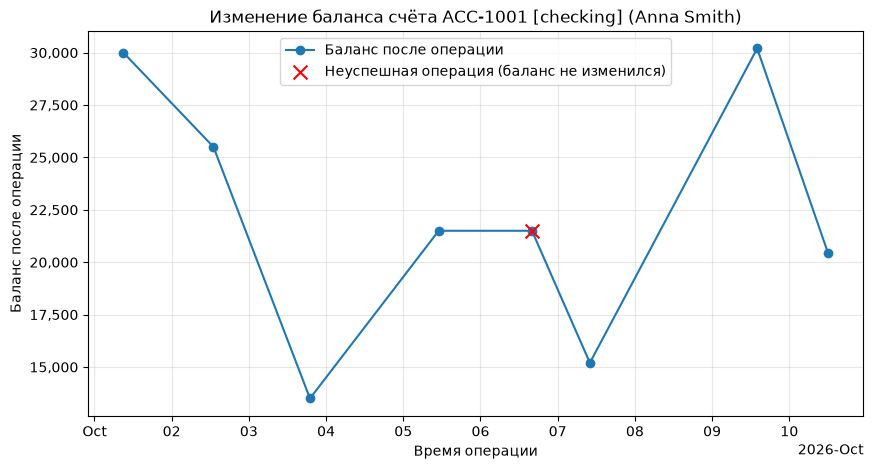

In [103]:
plot_balance_history(repo.get(second.id))
plt.show()

## Задание 2. Разные типы счетов и аналитика

**Объектная модель.**
- `BankAccount` – общая логика любого счёта: владелец (имя проверяется регулярным выражением), баланс, история и базовое правило снятия «не больше, чем есть» (`withdraw_error`).
- `CheckingAccount` (расчётный) ничего не добавляет к базовым правилам, только задаёт тип.
- `SavingsAccount` (сберегательный) переопределяет только то, чем отличается: разрешает операцию `interest` и добавляет к правилу снятия лимит 50% текущего баланса.
- Тип счёта различим и у объекта (класс и атрибут `account_type`), и в данных (поле `type` в JSON-базе).

`BankAccountService` один для всех типов: все операции проходят через `execute`, а правила берутся из модели счёта, поэтому они нигде не дублируются.

### Создание расчётного и сберегательного счетов

In [104]:
checking = repo.create("Иван Петров", 20_000, AccountType.CHECKING)
savings = repo.create("Maria Ivanova", 50_000, AccountType.SAVINGS)
checking_service = BankAccountService(checking, repo)
savings_service = BankAccountService(savings, repo)

for acc in (checking, savings):
    print(f"{acc}  ->  {type(acc).__name__}, account_type={acc.account_type}")

print("\nТип счёта в данных (JSON-база):")
for acc_id in (checking.id, savings.id):
    print(f"  {acc_id}: type = {db.read()['accounts'][acc_id]['type']!r}")
print("\nПосле чтения из базы:", type(repo.get(savings.id)).__name__)

ACC-1002 | checking | Иван Петров | balance: 20,000.00  ->  CheckingAccount, account_type=AccountType.CHECKING
ACC-1003 | savings | Maria Ivanova | balance: 50,000.00  ->  SavingsAccount, account_type=AccountType.SAVINGS

Тип счёта в данных (JSON-база):
  ACC-1002: type = 'checking'
  ACC-1003: type = 'savings'

После чтения из базы: SavingsAccount


### Начисление процентов на сберегательном счёте

Ставку задаёт вызывающий код (`7` = 7%), проценты считаются от текущего остатка и округляются до копеек. На расчётном счёте операция `interest` запрещена.

In [105]:
print(f"Баланс до: {savings_service.get_balance():,.2f}")
print(savings_service.accrue_interest(7))
print(f"Баланс после: {savings_service.get_balance():,.2f}")

try:
    checking_service.accrue_interest(7)
except TypeError as e:
    print("\nРасчётный счёт ->", type(e).__name__, ":", e)

Баланс до: 50,000.00
2026-10-19 13:32:57 | interest |     3,500.00 | balance after:      53,500.00 | success
Баланс после: 53,500.00

Расчётный счёт -> TypeError : Operation 'interest' is not allowed for checking account.


### Ограничение снятия на сберегательном счёте

Снять больше 50% текущего баланса нельзя: баланс не меняется, попытка фиксируется со статусом `fail` и причиной. На расчётном счёте такого ограничения нет.

In [106]:
balance = savings_service.get_balance()
print(f"Баланс сберегательного: {balance:,.2f}, лимит снятия: {balance / 2:,.2f}")
print(savings_service.withdraw(30_000))  # больше 50% -> fail
print(savings_service.withdraw(20_000))  # не больше 50% -> success
print(f"Баланс сберегательного: {savings_service.get_balance():,.2f}")

print(f"\nБаланс расчётного: {checking_service.get_balance():,.2f}")
print(checking_service.withdraw(15_000))  # 75% баланса - на расчётном можно

Баланс сберегательного: 53,500.00, лимит снятия: 26,750.00
2026-10-19 13:32:57 | withdraw |    30,000.00 | balance after:      53,500.00 | fail | exceeds 50% of balance
2026-10-19 13:32:57 | withdraw |    20,000.00 | balance after:      33,500.00 | success
Баланс сберегательного: 33,500.00

Баланс расчётного: 20,000.00
2026-10-19 13:32:57 | withdraw |    15,000.00 | balance after:       5,000.00 | success


### Последние крупные успешные операции

Порог «крупности» и N задаёт вызывающий код. Неуспешные операции в выборку не попадают, даже если сумма большая. Результат удобно показать таблицей через pandas.

In [107]:
for amount in (3_000, 12_000, 500, 7_000):
    checking_service.deposit(amount)
checking_service.withdraw(9_000)
checking_service.withdraw(50_000)  # крупная, но неуспешная
checking_service.withdraw(800)

print(checking_service.format_history())

large = checking_service.get_large_operations(threshold=5_000, n=3)
print("\nПоследние 3 успешные операции от 5 000:")
transactions_to_dataframe(large)[["date", "operation", "amount", "balance_after", "status"]]

История операций ACC-1002 (Иван Петров):
   1. 2026-10-19 13:32:57 | withdraw |    15,000.00 | balance after:       5,000.00 | success
   2. 2026-10-19 13:32:57 | deposit  |     3,000.00 | balance after:       8,000.00 | success
   3. 2026-10-19 13:32:57 | deposit  |    12,000.00 | balance after:      20,000.00 | success
   4. 2026-10-19 13:32:57 | deposit  |       500.00 | balance after:      20,500.00 | success
   5. 2026-10-19 13:32:57 | deposit  |     7,000.00 | balance after:      27,500.00 | success
   6. 2026-10-19 13:32:57 | withdraw |     9,000.00 | balance after:      18,500.00 | success
   7. 2026-10-19 13:32:57 | withdraw |    50,000.00 | balance after:      18,500.00 | fail | insufficient funds
   8. 2026-10-19 13:32:57 | withdraw |       800.00 | balance after:      17,700.00 | success

Последние 3 успешные операции от 5 000:


,date,operation,amount,balance_after,status
0,2026-10-19 13:32:57.932163,withdraw,9000.0,18500.0,success
1,2026-10-19 13:32:57.931674,deposit,7000.0,27500.0,success
2,2026-10-19 13:32:57.930612,deposit,12000.0,20000.0,success


### Некорректное имя владельца и некорректная сумма

Имя проверяется регулярным выражением: «Имя Фамилия», оба слова с заглавной буквы, только кириллица или только латиница. Неверное имя или сумма – исключение; счёт не создаётся, номер счёта не расходуется.

In [108]:
next_number = db.read()["next_account_number"]
for name in ("иван петров", "Ivan Петров", "Ivan", "Ivan Petrov2", "IVAN PETROV", 42):
    try:
        repo.create(name)
    except (ValueError, TypeError) as e:
        print(f"{name!r:>15} -> {type(e).__name__}: {str(e).split('.')[0]}")
print("Номер следующего счёта не изменился:", db.read()["next_account_number"] == next_number)

print()
for call, bad in ((savings_service.withdraw, -500), (savings_service.deposit, "сто"),
                  (savings_service.deposit, 99.9), (savings_service.accrue_interest, 0)):
    try:
        call(bad)
    except (ValueError, TypeError) as e:
        print(f"{call.__name__}({bad!r}) -> {type(e).__name__}: {e}")

  'иван петров' -> ValueError: Invalid full name: 'иван петров'
  'Ivan Петров' -> ValueError: Invalid full name: 'Ivan Петров'
         'Ivan' -> ValueError: Invalid full name: 'Ivan'
 'Ivan Petrov2' -> ValueError: Invalid full name: 'Ivan Petrov2'
  'IVAN PETROV' -> ValueError: Invalid full name: 'IVAN PETROV'
             42 -> TypeError: Full name must be a string, not int
Номер следующего счёта не изменился: True

withdraw(-500) -> ValueError: Amount must be positive, got -500.
deposit('сто') -> ValueError: Invalid amount: 'сто'
deposit(99.9) -> TypeError: Amount must be Decimal, int or str, not float or bool.
accrue_interest(0) -> ValueError: Interest rate must be positive, got 0.


### Дополнительно: перевод между счетами

- При успехе сумма списывается у отправителя и зачисляется получателю. Обе записи получают общий `transfer_id` и номер второго счёта (`counterparty`) и сохраняются **одной транзакцией БД** (`repository.save(sender, recipient)`): либо оба счёта, либо ни один.
- Если списать нельзя (не хватает средств или лимит 50% сберегательного счёта), у отправителя фиксируется `fail` с тем же признаком перевода, а получатель не меняется.

In [109]:
def show_balances() -> None:
    print(f"  {checking.id}: {checking.balance:>10,.2f} | {savings.id}: {savings.balance:>10,.2f}")

print("До переводов:")
show_balances()

print("\n1) Расчётный -> сберегательный, 2 000:")
print(" ", checking_service.transfer(savings, 2_000))
show_balances()

print("\n2) Сберегательный -> расчётный, 20 000 (больше 50% сберегательного):")
print(" ", savings_service.transfer(checking, 20_000))
show_balances()

print("\n3) Сберегательный -> расчётный, 10 000:")
print(" ", savings_service.transfer(checking, 10_000))
show_balances()

try:
    checking_service.transfer(checking, 100)
except ValueError as e:
    print("\nПеревод самому себе ->", e)

До переводов:
  ACC-1002:  17,700.00 | ACC-1003:  33,500.00

1) Расчётный -> сберегательный, 2 000:
  2026-10-19 13:32:58 | withdraw |     2,000.00 | balance after:      15,700.00 | success | transfer TR-25327E25 to ACC-1003
  ACC-1002:  15,700.00 | ACC-1003:  35,500.00

2) Сберегательный -> расчётный, 20 000 (больше 50% сберегательного):
  2026-10-19 13:32:58 | withdraw |    20,000.00 | balance after:      35,500.00 | fail | transfer TR-3DE28A25 to ACC-1002 | exceeds 50% of balance
  ACC-1002:  15,700.00 | ACC-1003:  35,500.00

3) Сберегательный -> расчётный, 10 000:
  2026-10-19 13:32:58 | withdraw |    10,000.00 | balance after:      25,500.00 | success | transfer TR-2DEFCBBE to ACC-1002
  ACC-1002:  25,700.00 | ACC-1003:  25,500.00

Перевод самому себе -> Cannot transfer to the same account.


Записи переводов в историях обоих счетов (данные заново прочитаны из базы): у списания и зачисления один `transfer_id`, а `counterparty` указывает на второй счёт. У неуспешного перевода есть только запись отправителя.

In [110]:
transfers = pd.concat(
    [BankAccountService(repo.get(acc.id)).history_dataframe().assign(account=acc.id)
     for acc in (checking, savings)]
)
(transfers.dropna(subset=["transfer_id"])
 .sort_values(["date", "transfer_id", "operation"], ascending=[True, True, False])
 [["transfer_id", "account", "operation", "amount", "balance_after", "status", "counterparty", "reason"]]
 .reset_index(drop=True))

,transfer_id,account,operation,amount,balance_after,status,counterparty,reason
0,TR-25327E25,ACC-1002,withdraw,2000.0,15700.0,success,ACC-1003,NaN
1,TR-25327E25,ACC-1003,deposit,2000.0,35500.0,success,ACC-1002,NaN
2,TR-3DE28A25,ACC-1003,withdraw,20000.0,35500.0,fail,ACC-1002,exceeds 50% of balance
3,TR-2DEFCBBE,ACC-1003,withdraw,10000.0,25500.0,success,ACC-1002,NaN
4,TR-2DEFCBBE,ACC-1002,deposit,10000.0,25700.0,success,ACC-1003,NaN


## Задание 3. Загрузка «грязных» данных

`TransactionImporter` читает CSV или JSON и загружает в конкретный счёт только операции нужного номера из файла:

1. **Чтение.** Все значения приводятся к строкам; пустые (`None`/`NaN`/пустая строка) – к `""`. Номер строки данных (`row`) сохраняется для отчёта.
2. **Фильтрация.** Остаются только строки с номером `source_account`; тип счёта в строке должен совпадать с типом целевого счёта.
3. **Проверка каждой строки.** Отбрасываются дубликаты, пустые и битые даты, пустой тип операции и опечатки в нём (`diposit`, `wdraw`), операции, недопустимые для типа счёта (`interest` на расчётном), пустые, нечисловые, отрицательные и нулевые суммы, неверный статус (`succes`). Даты принимаются в двух встречающихся в данных форматах (`2025-09-28 22:17:26` и `28/09/2025 22:17`).
4. **Проведение операций.** Валидные операции проводятся по времени через тот же `BankAccountService`, что и обычные. Поэтому баланс соответствует последовательности принятых операций и правилам типа счёта, а `balance_after` из файла не используется. Счёт сохраняется в базу один раз, одной транзакцией.

Начальные балансы взяты такими, какими они были до первой операции в файле: 1 200 для `ACC-100001` (первая строка: 921 → 2 121) и 1 500 для `ACC-100002` (469 → 1 969).

In [111]:
importer = TransactionImporter(repo)

raw_csv = importer.read_file("data/transactions_dirty.csv")
raw_json = importer.read_file("data/transactions_dirty.json")
print("Строк в файле:", len(raw_csv), "| счета:", raw_csv["account_number"].unique().tolist())
print("CSV и JSON после чтения совпадают:", raw_csv.equals(raw_json))
raw_csv.head()

Строк в файле: 105 | счета: ['ACC-100001', 'ACC-100002', 'ACC-100003', 'ACC-100004']
CSV и JSON после чтения совпадают: True


,row,account_number,account_type,date,operation,amount,balance_after,status
0,1,ACC-100001,checking,2025-09-27 22:17:26,deposit,921.0,2121.0,success
1,2,ACC-100001,checking,2025-09-27 22:17:26,deposit,607.0,2728.0,success
2,3,ACC-100001,checking,2025-09-28 22:17:26,deposit,488.0,3216.0,success
3,4,ACC-100001,checking,28/09/2025 22:17,deposit,129.0,3345.0,success
4,5,ACC-100001,checking,2025-09-29 22:17:26,deposit,880.0,4225.0,success


### Загрузка из CSV в расчётный счёт

In [112]:
csv_checking = repo.create("Ivan Sidorov", 1_200, AccountType.CHECKING)
csv_report = importer.load(csv_checking, "data/transactions_dirty.csv", source_account="ACC-100001")
print(csv_report.summary())
print("\nОбновлённый счёт:", csv_checking)

Загрузка transactions_dirty.csv: строки ACC-100001 -> счёт ACC-1004
  строк других счетов пропущено: 79
  строк этого счёта: 26
  принято: 17
  отклонено: 9
  причины отклонения:
    - interest недопустим для счёта checking: 2
    - битая дата: 2
    - пустая сумма: 1
    - пустой тип операции: 1
    - опечатка в типе операции: 1
    - неверный статус: 1
    - дубликат строки: 1

Обновлённый счёт: ACC-1004 | checking | Ivan Sidorov | balance: 4,864.00


Отчёт об отбраковке: какие строки отклонены и почему (`row` – номер строки данных в файле).

In [113]:
csv_report.rejected[["row", "date", "operation", "amount", "status", "reason"]]

,row,date,operation,amount,status,reason
0,6,2025-09-29 22:17:26,withdraw,,success,пустая сумма
1,9,2025-10-01 22:17:26,,654.0,success,пустой тип операции
2,11,2025-10-03 22:17:26,interest,532.0,success,interest недопустим для счёта checking
3,14,2025-17-34 12:00:00,deposit,793.0,success,битая дата
4,16,2025-10-06 22:17:26,diposit,669.0,success,опечатка в типе операции
5,17,2025-10-08 22:17:26,interest,744.0,success,interest недопустим для счёта checking
6,18,2023-16-40 12:00:00,withdraw,111.0,success,битая дата
7,25,2025-10-19 22:17:26,deposit,916.0,succes,неверный статус
8,105,2025-10-16 22:17:26,withdraw,393.0,success,дубликат строки


Фрагмент загруженной истории (данные прочитаны из базы):

In [114]:
BankAccountService(repo.get(csv_checking.id)).history_dataframe().head(8)

,date,operation,amount,balance_after,status,transfer_id,counterparty,reason
0,2025-09-27 22:17:26,deposit,921.0,2121.0,success,None,None,None
1,2025-09-27 22:17:26,deposit,607.0,2728.0,success,None,None,None
2,2025-09-28 22:17:00,deposit,129.0,2857.0,success,None,None,None
3,2025-09-28 22:17:26,deposit,488.0,3345.0,success,None,None,None
4,2025-09-29 22:17:26,deposit,880.0,4225.0,success,None,None,None
5,2025-10-01 22:17:26,withdraw,352.0,3873.0,success,None,None,None
6,2025-10-01 22:17:26,withdraw,65.0,3808.0,success,None,None,None
7,2025-10-01 22:17:26,withdraw,245.0,3563.0,success,None,None,None


### Загрузка из JSON в сберегательный счёт

In [115]:
json_savings = repo.create("Maria Smirnova", 1_500, AccountType.SAVINGS)
json_report = importer.load(json_savings, "data/transactions_dirty.json", source_account="ACC-100002")
print(json_report.summary())
print("\nОбновлённый счёт:", json_savings)
json_report.rejected[["row", "date", "operation", "amount", "status", "reason"]]

Загрузка transactions_dirty.json: строки ACC-100002 -> счёт ACC-1005
  строк других счетов пропущено: 78
  строк этого счёта: 27
  принято: 18
  отклонено: 9
  причины отклонения:
    - отрицательная или нулевая сумма: 2
    - опечатка в типе операции: 2
    - неверный статус: 2
    - дубликат строки: 2
    - битая дата: 1
    - пустая сумма: 1

Обновлённый счёт: ACC-1005 | savings | Maria Smirnova | balance: 3,991.24


,row,date,operation,amount,status,reason
0,29,2023-22-32 12:00:00,deposit,797.0,success,битая дата
1,30,2025-09-30 22:17:26,interest,,success,пустая сумма
2,34,2025-10-08 22:17:26,deposit,-136.0,success,отрицательная или нулевая сумма
3,38,2025-10-09 22:17:26,diposit,432.0,success,опечатка в типе операции
4,45,2025-10-16 22:17:26,deposit,-872.0,success,отрицательная или нулевая сумма
5,47,2025-10-19 22:17:26,withdraw,300.0,succes,неверный статус
6,49,2025-10-22 22:17:26,wdraw,457.0,success,опечатка в типе операции
7,101,09/10/2025 22:17,deposit,638.0,success,дубликат строки
8,104,2025-10-19 22:17:26,withdraw,300.0,succes,дубликат строки; неверный статус


In [116]:
BankAccountService(repo.get(json_savings.id)).history_dataframe().tail(8)

,date,operation,amount,balance_after,status,transfer_id,counterparty,reason
10,2025-10-10 22:17:26,interest,306.26,4931.98,success,None,None,None
11,2025-10-12 22:17:26,withdraw,278.00,4653.98,success,None,None,None
12,2025-10-13 22:17:26,withdraw,440.00,4213.98,success,None,None,None
13,2025-10-14 22:17:26,withdraw,231.00,3982.98,success,None,None,None
14,2025-10-15 22:17:26,interest,274.13,4257.11,success,None,None,None
15,2025-10-17 22:17:26,withdraw,286.00,3971.11,success,None,None,None
16,2025-10-20 22:17:26,interest,302.13,4273.24,success,None,None,None
17,2025-10-23 22:17:26,withdraw,282.00,3991.24,success,None,None,None


### Проверка: баланс соответствует принятым операциям

Пересчитываем баланс по истории: начальный баланс плюс пополнения и проценты минус снятия (только успешные операции). Также проверяем, что `balance_after` каждой записи продолжает предыдущую.

In [117]:
def check_balance(account: BankAccount, opening: Decimal) -> None:
    balance = opening
    chain_ok = True
    for t in account.history:
        if t.is_success:
            balance += -t.amount if t.operation is OperationType.WITHDRAW else t.amount
        chain_ok &= balance == t.balance_after
    print(f"{account.id}: пересчитано {balance:,.2f} | баланс счёта {account.balance:,.2f} | "
          f"совпадает: {balance == account.balance} | цепочка balance_after верна: {chain_ok}")


check_balance(repo.get(csv_checking.id), Decimal("1200"))
check_balance(repo.get(json_savings.id), Decimal("1500"))

ACC-1004: пересчитано 4,864.00 | баланс счёта 4,864.00 | совпадает: True | цепочка balance_after верна: True
ACC-1005: пересчитано 3,991.24 | баланс счёта 3,991.24 | совпадает: True | цепочка balance_after верна: True


### Фильтрация по типу счёта

Если загружать строки сберегательного счёта `ACC-100002` в расчётный счёт, все они отклоняются: тип в файле не совпадает, а `interest` на расчётном недопустим. Баланс счёта не меняется.

In [118]:
wrong_type = repo.create("Petr Volkov", 1_000, AccountType.CHECKING)
wrong_report = importer.load(wrong_type, "data/transactions_dirty.csv", source_account="ACC-100002")
print(wrong_report.summary())
print("\nСчёт:", wrong_type)

Загрузка transactions_dirty.csv: строки ACC-100002 -> счёт ACC-1006
  строк других счетов пропущено: 78
  строк этого счёта: 27
  принято: 0
  отклонено: 27
  причины отклонения:
    - тип счёта в файле не checking: 27
    - interest недопустим для счёта checking: 6
    - отрицательная или нулевая сумма: 2
    - опечатка в типе операции: 2
    - неверный статус: 2
    - дубликат строки: 2
    - битая дата: 1
    - пустая сумма: 1

Счёт: ACC-1006 | checking | Petr Volkov | balance: 1,000.00


### График баланса загруженного счёта

Та же функция из этапа 2: данные берутся из истории через pandas.

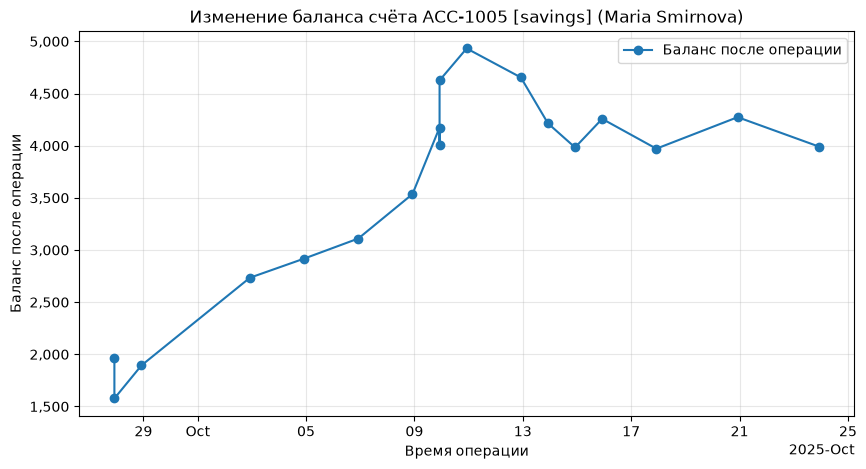

In [119]:
plot_balance_history(repo.get(json_savings.id))
plt.show()